# 03 · LightGBM global dengan fitur lag

**Tujuan notebook:** membangun satu model **global** (satu LightGBM untuk semua 3.049 item sekaligus), membandingkannya dengan baseline dan model statistik dari notebook 02 memakai backtest yang sama, lalu memahami *kenapa* model itu memprediksi seperti itu (feature importance dan SHAP).

**Model global vs lokal.** ETS/SARIMAX adalah model *lokal*: satu model per series, dan setiap model hanya belajar dari histori series itu sendiri. LightGBM di sini *global*: semua item masuk dalam satu tabel, sehingga pola yang sama (efek akhir pekan, efek harga) dipelajari dari jutaan baris. Item yang jarang terjual ikut terbantu oleh pola dari item lain.

**Setup (semua dari `configs/config.yaml`):**
- Strategi **direct** dengan horizon 28 hari. Semua fitur penjualan memakai data **≤ t − 28**, jadi satu model bisa langsung memprediksi hari ke-1 sampai ke-28 tanpa butuh prediksi hari sebelumnya.
- Per fold: early stopping di **28 hari terakhir data training** (bukan di jendela validasi), lalu model di-*refit* di seluruh data training dengan jumlah iterasi terbaik. Jendela validasi fold benar-benar tidak terlihat sampai dinilai.
- Test set (d_1914–d_1941) **tidak dimuat** di notebook ini.

Prediksi dihasilkan oleh `python -m scripts.run_backtest --model lgbm_*` dan tuning oleh `python -m scripts.tune_lgbm`. Notebook ini membaca hasilnya dari `reports/results/`. Satu-satunya model yang dilatih di sini adalah model untuk SHAP (bagian 6).

In [1]:
import json

import numpy as np
import pandas as pd
import plotly.io as pio

from forecasting.config import load_config, resolve_path
from forecasting.evaluation.explain import mean_abs_shap, shap_sample
from forecasting.evaluation.metrics import metrics_by_horizon, per_series_rmsse
from forecasting.features.build import feature_groups
from forecasting.models.registry import make_model
from forecasting.validation.backtest import generate_folds, load_feature_data, load_level_data
from forecasting.viz import plots

pio.renderers.default = "png"
pio.renderers["png"].width = 1000
pd.set_option("display.float_format", "{:,.4f}".format)

config = load_config()
folds = generate_folds(config)
RESULTS = resolve_path(config, "results")
PREDS = RESULTS / "preds"
board = pd.read_csv(RESULTS / "leaderboard_cv.csv")
items = load_level_data(config, "item")  # d <= 1913: the test window is never loaded
classes = pd.read_parquet(resolve_path(config, "processed") / "item_classes.parquet")
sample = pd.read_csv(resolve_path(config, "processed") / "stat_sample_items.csv")
LGBM = ["lgbm_tweedie", "lgbm_poisson", "lgbm_l2", "lgbm_tuned"]

## 1 · Fitur: apa yang dilihat model?

Ada 38 fitur dalam 5 grup:

| Grup | Isi | Kenapa aman dari leakage |
|---|---|---|
| **lag** | `lag_28 … lag_56`, `lag_364`, rolling mean/std 7–112 hari, rasio mean 7/28 | semua di-*shift* ≥ 28 hari |
| **calendar** | hari dalam minggu, bulan, event, SNAP, jarak ke/dari event | kalender sudah diketahui jauh hari |
| **price** | harga jual, perubahan 1 minggu, momentum 28 hari, rank harga di departemen, harga relatif terhadap rata-rata item | harga dijadwalkan toko sebelumnya; rata-rata item dihitung **per fold** dari data training saja |
| **identity** | `series_id`, `dept_id`, `cat_id` (kategori native LightGBM) | statis |
| **intermittency** | panjang run nol per *t − 28*, kelas demand (dihitung ≤ d_1801) | di-*shift* 28 hari / dihitung sebelum fold pertama |

> **Leakage** = model tanpa sengaja melihat informasi yang belum tersedia saat prediksi dibuat. Contoh: `lag_7` terlihat sangat membantu di backtest, padahal saat memprediksi hari ke-20 penjualan 7 hari sebelumnya belum terjadi. Setiap fungsi fitur punya unit test di `tests/test_features_leakage.py`: penjualan setelah cutoff diubah acak, lalu dicek bahwa fitur di 28 hari berikutnya tidak berubah sedikit pun.

In [2]:
groups = feature_groups(config)
pd.DataFrame(
    [{"grup": g, "jumlah": len(cols), "fitur": ", ".join(cols)} for g, cols in groups.items()]
)

,grup,jumlah,fitur
0,lag,17,"lag_28, lag_35, lag_42, lag_49, lag_56, lag_36..."
1,calendar,11,"day_of_week, day_of_month, week_of_year, month..."
2,price,5,"sell_price, price_change_1w, price_momentum, p..."
3,identity,3,"series_id, dept_id, cat_id"
4,intermittency,2,"zero_run_len_lag, demand_class"


## 2 · Pilihan objective: tweedie vs poisson vs L2

72% item kita *intermittent* (banyak hari nol, sesekali terjual). Fungsi loss menentukan bagaimana model memperlakukan pola itu:
- **L2 (regression):** meminimalkan kuadrat error. Sederhana, tapi bisa memprediksi nilai negatif dan menganggap distribusi simetris.
- **Poisson:** cocok untuk data hitungan (count). Prediksinya selalu positif.
- **Tweedie:** campuran "nol atau positif kontinu", populer di kompetisi M5 untuk penjualan intermittent. Parameter `tweedie_variance_power` (antara 1 dan 2) mengatur seberapa "berat" massa di nol.

**Insight:** ketiga varian LightGBM mengalahkan benchmark Moving Average 28 hari (0,841) di semua item. **Tweedie** menjadi objective terbaik (0,8045), sehingga dipakai sebagai dasar tuning, dan versi tuned-nya turun lagi ke **0,8010**. Selisih antar-objective kecil (±0,5%) di level item. Perbedaan besar justru muncul di level agregat (bagian 4).

Perlu dicatat: WAPE item ±0,75 terlihat tinggi, tapi ini wajar untuk penjualan harian per item yang mayoritas 0–2 unit. Error relatif di level item memang selalu besar, dan karena itulah metrik utama memakai skala (RMSSE), bukan persentase.

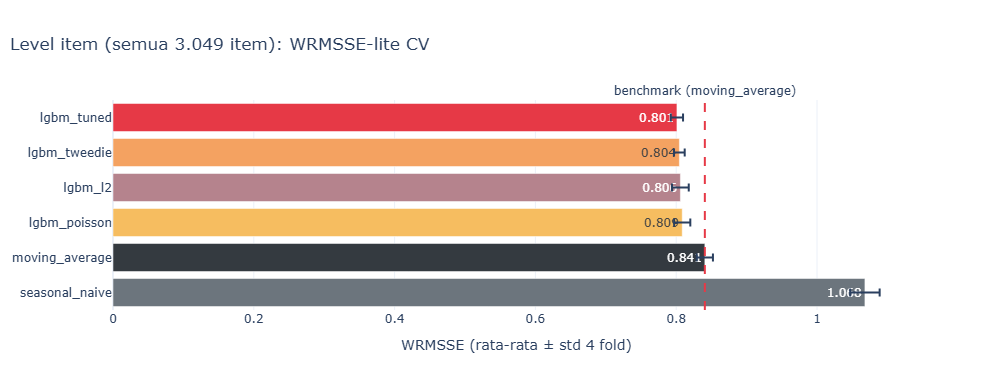

,model,wrmsse_mean,wrmsse_std,rmsse_mean,wape_mean,bias_mean,runtime_sec_total
0,lgbm_tuned,0.8010,0.0087,0.6889,0.7473,-0.0296,760.4208
1,lgbm_tweedie,0.8045,0.0076,0.6894,0.7496,-0.0263,550.8794
2,lgbm_l2,0.8059,0.0119,0.7035,0.7666,-0.0042,324.7568
3,lgbm_poisson,0.8086,0.0115,0.6970,0.7611,-0.0178,824.5830
4,moving_average,0.8407,0.0115,0.6939,0.7595,-0.0230,5.6229
5,seasonal_naive,1.0681,0.0209,0.8990,0.8860,-0.0384,4.5973


In [3]:
cols = [
    "model",
    "wrmsse_mean",
    "wrmsse_std",
    "rmsse_mean",
    "wape_mean",
    "bias_mean",
    "runtime_sec_total",
]
b_all = board[
    (board["level"] == "item")
    & (board["subset"] == "all")
    & board["model"].isin([*LGBM, "moving_average", "seasonal_naive"])
]
fig = plots.plot_leaderboard(
    b_all,
    "wrmsse",
    benchmark="moving_average",
    title="Level item (semua 3.049 item): WRMSSE-lite CV",
)
fig.show()
plots.save_png(fig, "16_leaderboard_lgbm_item", config)
b_all[cols].reset_index(drop=True)

## 3 · Tuning hyperparameter dengan Optuna

> **Optuna** mencari kombinasi hyperparameter secara bertahap. Sampler **TPE** belajar dari trial sebelumnya: area parameter yang hasilnya bagus lebih sering dicoba lagi. **MedianPruner** menghentikan trial lebih awal kalau setelah fold F2 skornya lebih buruk dari median trial lain, supaya waktu tidak terbuang.

Skor setiap trial = rata-rata WRMSSE-lite di **4 fold backtest yang sama**. Test set tidak dipakai sama sekali.

**Insight:**
- 30 trial (5 di-prune) menurunkan WRMSSE dari 0,8045 (default) ke **0,8010**. Peningkatannya kecil (±0,4%) dan masih di dalam simpangan antar-fold (±0,009). Artinya parameter default sudah cukup baik, dan sumber akurasi utama ada di **fitur**, bukan di tuning.
- Pola parameter terbaik: **learning rate kecil** (0,021) dengan lebih banyak pohon, **`min_data_in_leaf` besar** (211, daun pohon tidak boleh terlalu spesifik), dan **`tweedie_variance_power` 1,37** (lebih tinggi dari default 1,1, cocok untuk data dengan banyak nol).
- Korelasi Spearman di tabel kedua mengonfirmasi hal yang sama: learning rate tinggi cenderung memperburuk skor (+0,45), sedangkan `bagging_fraction` dan `min_data_in_leaf` yang lebih besar cenderung membantu.

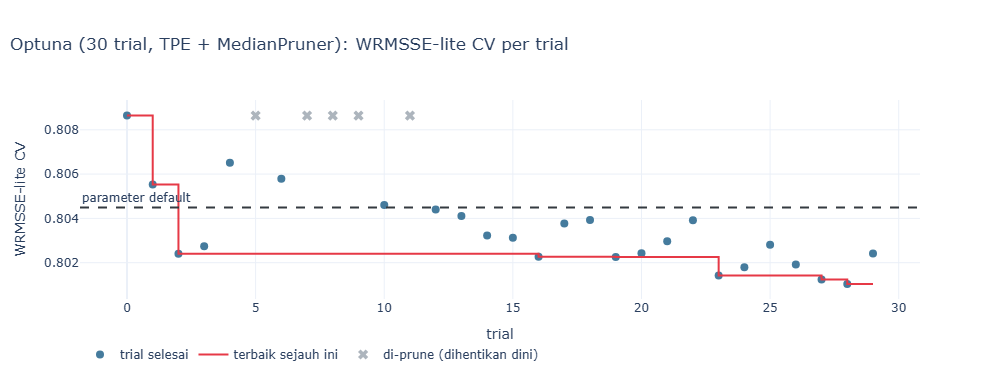

trial terbaik #28: WRMSSE 0.8010 | 5 dari 30 trial di-prune


,default,tuned
num_leaves,127.0000,93.0000
learning_rate,0.0500,0.0212
min_data_in_leaf,100.0000,211.0000
feature_fraction,0.8000,0.7672
bagging_fraction,0.8000,0.8718
lambda_l2,0.1000,0.0082
tweedie_variance_power,1.1000,1.3748


In [4]:
trials = pd.read_csv(RESULTS / "optuna_trials_lgbm.csv")
best = json.loads((RESULTS / "lgbm_best_params.json").read_text())
default_score = float(
    board.query("model == 'lgbm_tweedie' and level == 'item' and subset == 'all'")[
        "wrmsse_mean"
    ].iloc[0]
)
fig = plots.plot_optuna_history(
    trials,
    baseline=default_score,
    title="Optuna (30 trial, TPE + MedianPruner): WRMSSE-lite CV per trial",
)
fig.show()
plots.save_png(fig, "17_optuna_history", config)
print(
    f"trial terbaik #{best['trial']}: WRMSSE {best['cv_wrmsse']:.4f} | "
    f"{best['n_pruned']} dari {best['n_trials']} trial di-prune"
)
default = config["lgbm"]["params"]
pd.DataFrame({"default": {k: default.get(k) for k in best["params"]}, "tuned": best["params"]})

In [5]:
# which hyperparameters move the score? rank correlation with WRMSSE over completed trials
done = trials[trials["state"] == "COMPLETE"]
pcols = [c for c in done.columns if c.startswith("params_")]
done[pcols].corrwith(done["value"], method="spearman").rename("spearman vs WRMSSE").sort_values()

params_bagging_fraction         -0.5654
params_min_data_in_leaf         -0.3831
params_tweedie_variance_power   -0.2662
params_feature_fraction         -0.1885
params_num_leaves               -0.0758
params_lambda_l2                -0.0008
params_learning_rate             0.4531
Name: spearman vs WRMSSE, dtype: float64

## 4 · LightGBM vs model statistik

**Level agregat (11 series).** LightGBM tidak dilatih ulang untuk agregat. Prediksi 3.049 item cukup **dijumlahkan** (*bottom-up*) ke level departemen, kategori, dan toko. Hasilnya otomatis konsisten: jumlah prediksi departemen = prediksi kategori = prediksi toko.

**Insight:**
- LightGBM bottom-up adalah model **terbaik di level agregat**: RMSSE 0,546 (tweedie default) dan 0,564 (tuned), jauh di bawah SARIMAX (0,660) yang dilatih khusus per series agregat. WAPE total toko hanya ±7%.
- Menariknya, **versi tuned sedikit lebih buruk di agregat** dibanding default (0,564 vs 0,546), padahal lebih baik di level item. Tuning mengoptimalkan WRMSSE item, sehingga sedikit *trade-off* ke level lain wajar. Bias kedua versi sama-sama ±−3% (sedikit *under-forecast*), jadi perbedaannya bukan karena salah satu meleset sistematis.
- Di **200 item sampel** (perbandingan apple-to-apple dengan model statistik), LightGBM (0,723–0,724) setara dengan SARIMAX (0,727) dan lebih baik dari ETS (0,738) dan Prophet (0,812). Perbedaannya: LightGBM melatih **satu model untuk 3.049 item dalam ±3 menit per fold**, sedangkan SARIMAX butuh ratusan model terpisah.

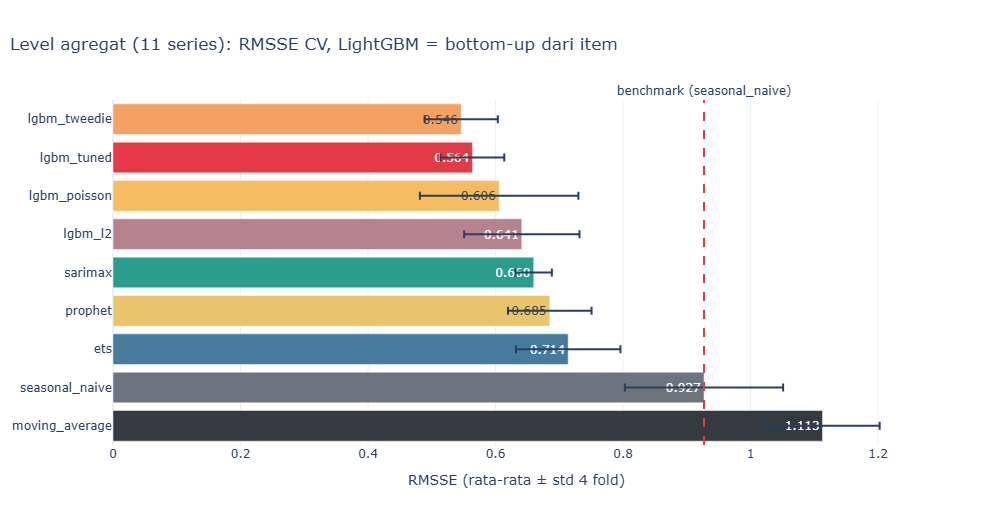

,model,rmsse_mean,rmsse_std,wape_mean,bias_mean
0,lgbm_tweedie,0.5462,0.0574,0.0688,-0.0263
1,lgbm_tuned,0.5638,0.0499,0.0707,-0.0296
2,lgbm_poisson,0.6056,0.1243,0.0715,-0.0178
3,lgbm_l2,0.6412,0.0905,0.0735,-0.0042
4,sarimax,0.6599,0.0285,0.0886,-0.0350
5,prophet,0.6851,0.0655,0.0948,-0.0266
6,ets,0.7140,0.0820,0.0890,-0.0285
7,seasonal_naive,0.9270,0.1241,0.1274,-0.0384
8,moving_average,1.1128,0.0896,0.1827,-0.0231


In [6]:
b_agg = board[board["level"] == "agg"]
b_agg = b_agg[~b_agg["model"].isin(["lgbm_no_price", "lgbm_no_calendar", "naive"])]
fig = plots.plot_leaderboard(
    b_agg,
    "rmsse",
    benchmark="seasonal_naive",
    title="Level agregat (11 series): RMSSE CV, LightGBM = bottom-up dari item",
)
fig.show()
plots.save_png(fig, "18_leaderboard_agg_all", config)
b_agg[["model", "rmsse_mean", "rmsse_std", "wape_mean", "bias_mean"]].reset_index(drop=True)

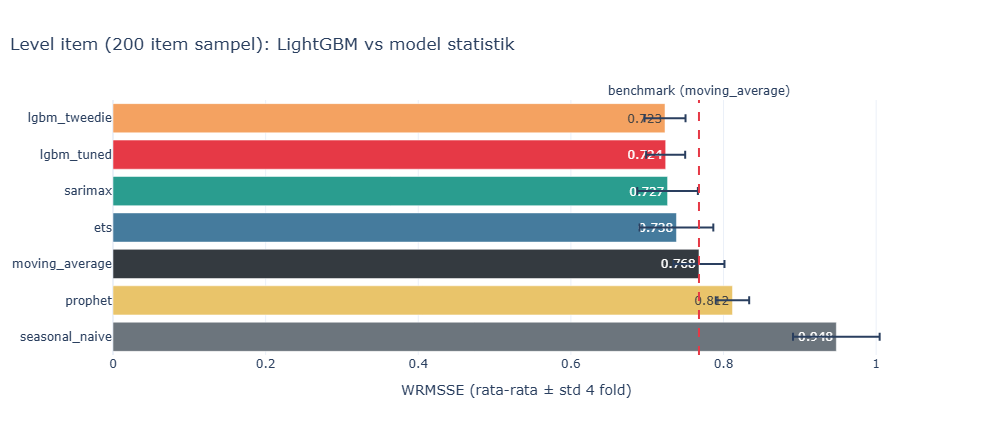

,model,wrmsse_mean,wrmsse_std,wape_mean,bias_mean
0,lgbm_tweedie,0.7233,0.0269,0.6162,-0.0172
1,lgbm_tuned,0.7242,0.0256,0.6165,-0.0186
2,sarimax,0.7267,0.0397,0.6130,-0.0093
3,ets,0.7383,0.0483,0.6181,-0.0346
4,moving_average,0.7678,0.0334,0.6341,-0.0222
5,prophet,0.8117,0.0219,0.6870,-0.0351
6,seasonal_naive,0.9478,0.0568,0.7544,-0.0533


In [7]:
b_s = board[(board["level"] == "item") & (board["subset"] == "stat_sample")]
b_s = b_s[
    b_s["model"].isin(
        [
            "lgbm_tuned",
            "lgbm_tweedie",
            "sarimax",
            "ets",
            "prophet",
            "moving_average",
            "seasonal_naive",
        ]
    )
]
fig = plots.plot_leaderboard(
    b_s,
    "wrmsse",
    benchmark="moving_average",
    title="Level item (200 item sampel): LightGBM vs model statistik",
)
fig.show()
plots.save_png(fig, "19_leaderboard_item_sample", config)
b_s[["model", "wrmsse_mean", "wrmsse_std", "wape_mean", "bias_mean"]].reset_index(drop=True)

## 5 · Feature importance (gain)

> **Gain** = total penurunan loss yang dihasilkan setiap kali fitur dipakai untuk memecah pohon. Gain menunjukkan fitur yang paling banyak "dipakai" model, tapi tidak menunjukkan **arah** pengaruhnya (naik atau turun). Untuk arah, kita pakai SHAP di bagian berikutnya.

**Insight:**
- **Rolling mean** mendominasi: `roll_mean_28` dan `roll_mean_56` saja menyumbang ±60% gain. Model pertama-tama bertanya "berapa level penjualan item ini akhir-akhir ini?", sama seperti Moving Average, tapi kemudian mengoreksinya dengan fitur lain.
- `series_id` (±10%) membuat model bisa menyimpan "kepribadian" tiap item yang tidak tertangkap fitur lag.
- Grup kalender dan harga hanya ±3% gain. Tapi gain kecil **bukan berarti tidak penting**: ablation di bagian 9 menunjukkan bahwa membuang kalender merusak forecast agregat. Gain mengukur seberapa sering fitur dipakai, bukan seberapa besar kontribusinya ke kualitas prediksi.
- `best_iteration` sangat berbeda antar-fold (1.147 di F1 vs ±300 di F2–F4). Inner validation 28 hari cukup *noisy*, sehingga jumlah pohon optimal ikut bervariasi.

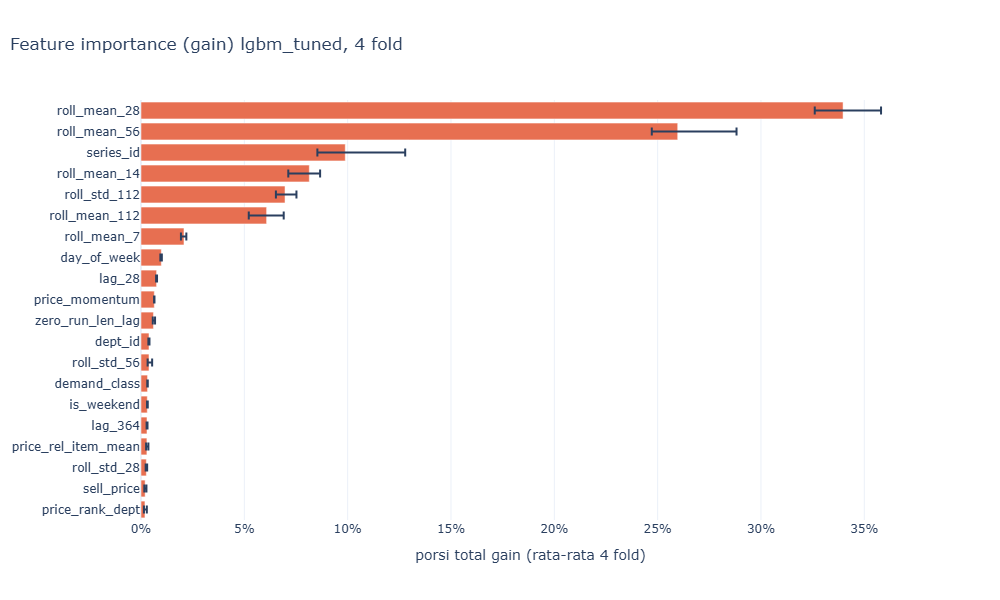

best_iteration per fold: {'F1': 1147, 'F2': 358, 'F3': 274, 'F4': 325}


,porsi gain
lag,0.8559
identity,0.1031
calendar,0.0185
price,0.0134
intermittency,0.0092


In [8]:
imp = pd.read_csv(RESULTS / "importance_lgbm_tuned.csv", index_col="feature")
best_iter = imp.loc["__best_iteration__"]
imp = imp.drop(index="__best_iteration__")
fig = plots.plot_importance(imp, top_n=20, title="Feature importance (gain) lgbm_tuned, 4 fold")
fig.show()
plots.save_png(fig, "20_importance_gain", config)
share = (imp / imp.sum()).mean(axis=1)
by_group = pd.Series({g: share.reindex(c).sum() for g, c in groups.items()}, name="porsi gain")
print("best_iteration per fold:", best_iter.astype(int).to_dict())
by_group.sort_values(ascending=False).to_frame()

## 6 · SHAP: bagaimana setiap fitur menggeser prediksi?

> **SHAP** (*SHapley Additive exPlanations*) membagi setiap prediksi menjadi kontribusi per fitur: prediksi = nilai dasar + Σ kontribusi fitur. Kontribusi positif mendorong prediksi naik, negatif menurunkannya. Karena objective tweedie bekerja di skala **log**, nilai SHAP 0,5 berarti prediksi dikali e^0,5 ≈ 1,65.

Model `lgbm_tuned` dilatih ulang di data training fold F4 (≤ d_1885), lalu dijelaskan pada **5.000 baris acak** dari jendela validasi F4 (seed 42). Kenapa sampel? TreeSHAP untuk ±85 ribu baris × 38 fitur tetap bisa dihitung, tapi 5.000 baris sudah cukup untuk melihat pola global dan jauh lebih ringan.

In [9]:
# Refit lgbm_tuned on fold F4's training data (d <= 1885) and explain its F4 forecasts.
f4 = folds[-1]
feats = load_feature_data(config)
model = make_model("lgbm_tuned", "item", config)().fit(feats[feats["d"] <= f4.train_end])
valid = feats[feats["d"].between(f4.valid_start, f4.valid_end)]
shap_vals, X_shap, base = shap_sample(
    model, valid, config["lgbm"]["shap_sample_rows"], config["seed"]
)
del feats
print(f"{len(X_shap):,} baris sampel | base value (log) = {base:.3f} -> {np.exp(base):.3f} unit")

5,000 baris sampel | base value (log) = -0.361 -> 0.697 unit


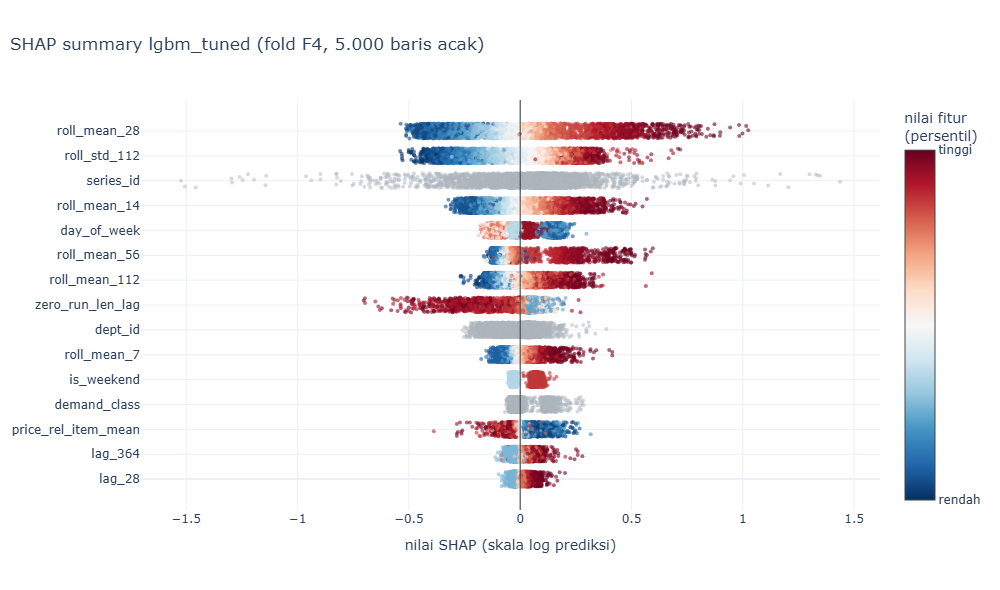

,mean |SHAP|,porsi gain,rank SHAP,rank gain
roll_mean_28,0.2178,0.3397,1,1
roll_std_112,0.1972,0.0697,2,5
series_id,0.1495,0.0988,3,3
roll_mean_14,0.1315,0.0814,4,4
day_of_week,0.0997,0.0098,5,8
roll_mean_56,0.0978,0.2597,6,2
roll_mean_112,0.0873,0.0608,7,6
zero_run_len_lag,0.0719,0.0060,8,11
dept_id,0.0565,0.0039,9,12
roll_mean_7,0.0521,0.0208,10,7


In [10]:
fig = plots.plot_shap_summary(
    shap_vals,
    X_shap,
    top_n=15,
    seed=config["seed"],
    title="SHAP summary lgbm_tuned (fold F4, 5.000 baris acak)",
)
fig.show()
plots.save_png(fig, "21_shap_summary", config)
compare = pd.DataFrame(
    {"mean |SHAP|": mean_abs_shap(shap_vals), "porsi gain": share.reindex(shap_vals.columns)}
)
compare["rank SHAP"] = compare["mean |SHAP|"].rank(ascending=False).astype(int)
compare["rank gain"] = compare["porsi gain"].rank(ascending=False).astype(int)
compare.sort_values("mean |SHAP|", ascending=False).head(15)

**Cara membaca grafik SHAP di atas:** setiap titik adalah satu baris (item × hari). Warna merah berarti nilai fitur tinggi, biru berarti rendah, dan abu-abu untuk fitur kategori.
- `roll_mean_28` tinggi (merah) → SHAP positif → prediksi naik. Item yang belakangan laris diprediksi tetap laris.
- `roll_std_112` tinggi (penjualan item naik-turun tajam dalam 4 bulan terakhir) → prediksi naik. Dugaan (belum diuji): penjualan yang volatil umumnya juga bervolume lebih besar.
- `zero_run_len_lag` tinggi (merah, sudah lama tidak terjual) → prediksi **turun** tajam. Fitur ini membantu model mengenali item yang sedang stockout atau mulai discontinued.
- `day_of_week` dan `is_weekend` memisahkan hari kerja dari akhir pekan dengan rapi (pola mingguan dari EDA).
- `price_rel_item_mean` tinggi (harga di atas rata-rata item) → prediksi turun. Arahnya sesuai teori ekonomi, walaupun efeknya kecil.

Urutan berdasarkan mean |SHAP| mirip dengan urutan gain (`roll_mean_28` tetap nomor 1), tetapi `roll_std_112`, `day_of_week`, `zero_run_len_lag`, dan `is_weekend` naik peringkat. Fitur-fitur ini jarang dipakai untuk split sehingga gain-nya kecil, tapi efeknya terasa di hampir setiap prediksi. Sebaliknya, `roll_mean_56` punya gain besar (nomor 2) tapi SHAP-nya hanya nomor 6, karena informasinya banyak tumpang tindih dengan `roll_mean_28`.

## 7 · Error per kelas demand

Tabel pertama memakai 200 item sampel (dibandingkan dengan model statistik), tabel kedua memakai **semua item** (dibandingkan dengan Moving Average).

**Insight:**
- Keunggulan LightGBM paling besar di item **smooth** (−4,5% RMSSE vs MA28) dan **erratic** (−3%). Ini item dengan sinyal cukup kuat sehingga pola mingguan, event, dan harga bisa dipelajari.
- Di item **intermittent** dan **lumpy** (±89% dari semua item), semua model hampir sama. Penjualan acak 0/1/2 unit memang sulit diprediksi lebih baik dari rata-rata. Di 200 sampel, untuk kelas lumpy ETS dan MA28 bahkan sedikit lebih baik.
- Skor keseluruhan (WRMSSE) dibobot **revenue**. Penurunan WRMSSE LightGBM terhadap MA28 (0,841 → 0,801) kalau dipecah per kelas: smooth menyumbang ±42%, intermittent ±41%, lumpy ±10%, erratic ±7%. Smooth hanya 24% revenue, tetapi perbaikannya besar. Intermittent perbaikannya kecil per item, tetapi bobotnya 60% revenue.
- Implikasi untuk Fase 7 (inventori): ketidakpastian item intermittent/lumpy tetap besar, sehingga **safety stock**-lah yang akan menanggung beban utama di kelas ini, bukan akurasi forecast.

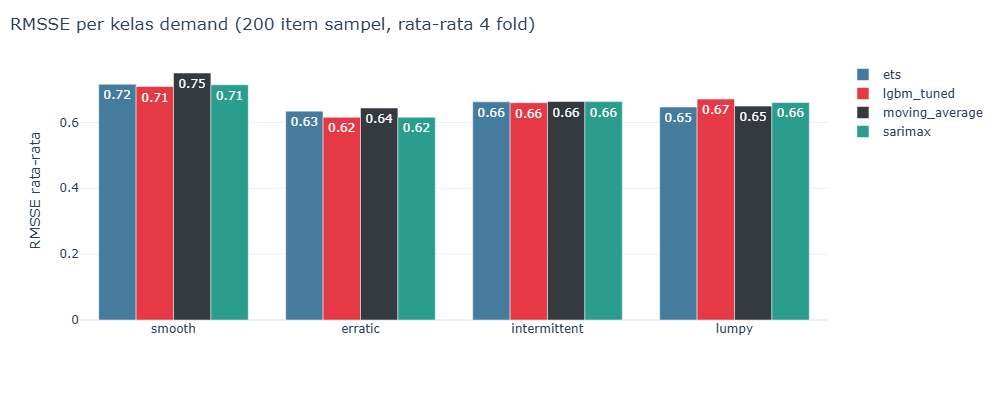

model,ets,lgbm_tuned,moving_average,sarimax
demand_class,,,,
smooth,0.7158,0.7091,0.7501,0.7143
erratic,0.6342,0.6156,0.6438,0.6159
intermittent,0.6625,0.6600,0.6635,0.6633
lumpy,0.6466,0.6708,0.6496,0.6606


In [11]:
def rmsse_by_class(models: list[str], ids: set[str] | None) -> pd.DataFrame:
    rows = []
    data = items if ids is None else items[items["series_id"].astype(str).isin(ids)]
    for m in models:
        p = pd.read_parquet(PREDS / f"{m}_item.parquet")
        if ids is not None:
            p = p[p["series_id"].astype(str).isin(ids)]
        rows.append(per_series_rmsse(p, data, folds).assign(model=m))
    per = pd.concat(rows).merge(
        classes[["item_id", "demand_class"]], left_on="series_id", right_on="item_id"
    )
    per = per[per["demand_class"].isin(["smooth", "erratic", "intermittent", "lumpy"])]
    out = per.groupby(["demand_class", "model"], observed=True)["rmsse"].mean().reset_index()
    out["demand_class"] = pd.Categorical(
        out["demand_class"].astype(str), ["smooth", "erratic", "intermittent", "lumpy"]
    )
    return out.sort_values(["demand_class", "model"])


ids = set(sample["item_id"].astype(str))
cls_s = rmsse_by_class(["moving_average", "ets", "sarimax", "lgbm_tuned"], ids)
fig = plots.plot_metric_by_group(
    cls_s,
    "demand_class",
    "rmsse",
    axis_title="RMSSE rata-rata",
    title="RMSSE per kelas demand (200 item sampel, rata-rata 4 fold)",
)
fig.show()
plots.save_png(fig, "22_rmsse_by_class_lgbm", config)
cls_s.pivot(index="demand_class", columns="model", values="rmsse")

In [12]:
cls_all = rmsse_by_class(["moving_average", "lgbm_tuned"], None)
piv = cls_all.pivot(index="demand_class", columns="model", values="rmsse")
piv["selisih (%)"] = 100 * (piv["lgbm_tuned"] / piv["moving_average"] - 1)
piv.join(classes["demand_class"].value_counts().rename("n_item"))

,lgbm_tuned,moving_average,selisih (%),n_item
demand_class,,,,
smooth,0.7196,0.7533,-4.4743,239
erratic,0.6058,0.6248,-3.0405,83
intermittent,0.6973,0.6995,-0.3064,2192
lumpy,0.6533,0.6548,-0.2227,533


## 8 · Error per hari horizon

Pada strategi *recursive*, error biasanya membesar seiring horizon karena prediksi hari ke-1 dipakai sebagai input hari ke-2, dan seterusnya. Pada strategi **direct** dengan lag ≥ 28, setiap hari horizon memakai informasi yang sama, jadi seharusnya tidak ada tren naik.

**Insight:**
- Benar: kurva WAPE **tidak menanjak** dari h = 1 ke h = 28. Yang terlihat adalah gelombang **mingguan**: error tinggi di hari dengan penjualan rendah (sedikit unit, sehingga error relatifnya besar) dan rendah di akhir pekan.
- LightGBM paling unggul di **puncak gelombang** (hari-hari tersulit), dengan WAPE maksimum 0,83 vs 0,91 untuk MA28. Di hari-hari termudah, keduanya setara.

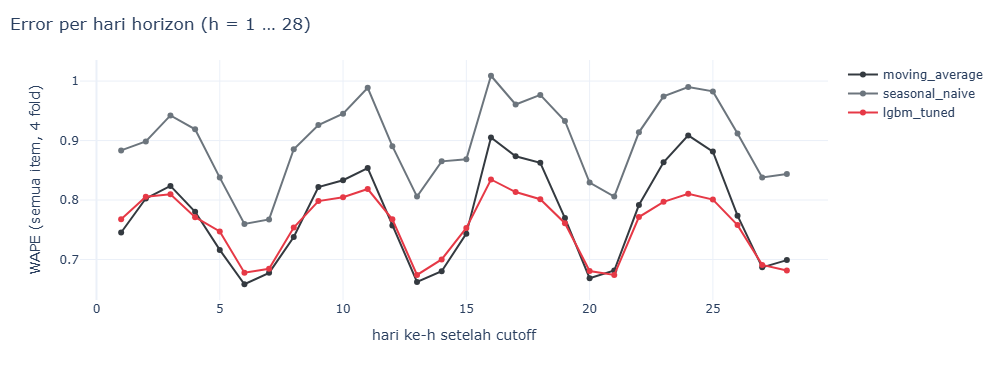

model,lgbm_tuned,moving_average,seasonal_naive
mean,0.7574,0.7735,0.8983
min,0.6739,0.6584,0.7598
max,0.8345,0.9087,1.0090


In [13]:
rows = []
for m in ["moving_average", "seasonal_naive", "lgbm_tuned"]:
    p = pd.read_parquet(PREDS / f"{m}_item.parquet")
    rows.append(metrics_by_horizon(p, folds).assign(model=m))
hz = pd.concat(rows)
fig = plots.plot_metric_by_horizon(
    hz, "wape", axis_title="WAPE (semua item, 4 fold)", title="Error per hari horizon (h = 1 … 28)"
)
fig.show()
plots.save_png(fig, "23_wape_by_horizon", config)
hz.pivot(index="h", columns="model", values="wape").describe().loc[["mean", "min", "max"]]

## 9 · Ablation: seberapa penting grup fitur harga dan kalender?

> **Ablation** = melatih ulang model dengan satu grup fitur dibuang, lalu melihat seberapa besar skornya memburuk. Cara ini lebih jujur daripada importance karena mengukur kontribusi nyata ke akurasi.

Kedua varian memakai hyperparameter tuned yang sama dan 4 fold yang sama.

**Insight:**
- **Tanpa kalender:** WRMSSE item memburuk **+3,1%**, dan RMSSE agregat melonjak **+79%** (0,564 → 1,010, lebih buruk dari Seasonal Naive). Tanpa hari dalam minggu dan event, model tidak bisa menangkap pola mingguan yang sangat kuat di level toko. Error tiap item yang kecil dan searah menumpuk saat dijumlahkan.
- **Tanpa harga:** WRMSSE item hanya memburuk **+0,4%**, dan agregat malah sedikit membaik (−0,9%). Di toko ini perubahan harga jarang terjadi (lihat EDA Q4), sehingga sinyal harga lemah. Fitur harga tetap dipertahankan karena membantu di level item (metrik utama) dan dibutuhkan untuk analisis *what-if* harga di dashboard.

In [14]:
abl = board[board["model"].isin(["lgbm_tuned", "lgbm_no_price", "lgbm_no_calendar"])]
abl = abl[(abl["subset"] == "all")].copy()
abl["skor"] = abl["wrmsse_mean"].fillna(abl["rmsse_mean"])
tbl = abl.pivot(index="model", columns="level", values="skor").rename(
    columns={"item": "WRMSSE item", "agg": "RMSSE agregat"}
)
ref = tbl.loc["lgbm_tuned"]
for c in ["WRMSSE item", "RMSSE agregat"]:
    tbl[f"Δ {c} (%)"] = 100 * (tbl[c] / ref[c] - 1)
tbl.loc[["lgbm_tuned", "lgbm_no_price", "lgbm_no_calendar"]]

level,RMSSE agregat,WRMSSE item,Δ WRMSSE item (%),Δ RMSSE agregat (%)
model,,,,
lgbm_tuned,0.5638,0.8010,0.0000,0.0000
lgbm_no_price,0.5587,0.8039,0.3624,-0.9039
lgbm_no_calendar,1.0096,0.8260,3.1224,79.0711


## 10 · Contoh: total toko CA_1 di fold F4

Garis merah = jumlah prediksi 3.049 item LightGBM (bottom-up). Garis hijau = SARIMAX yang dilatih langsung di series total toko.

**Insight:** LightGBM mengikuti puncak akhir pekan lebih dekat daripada SARIMAX, yang cenderung meredam puncak. Keduanya masih meleset di puncak tertinggi (±6.500 unit di awal April). Seasonal Naive hanya menyalin minggu lalu, sehingga ikut menyalin anomali minggu itu.

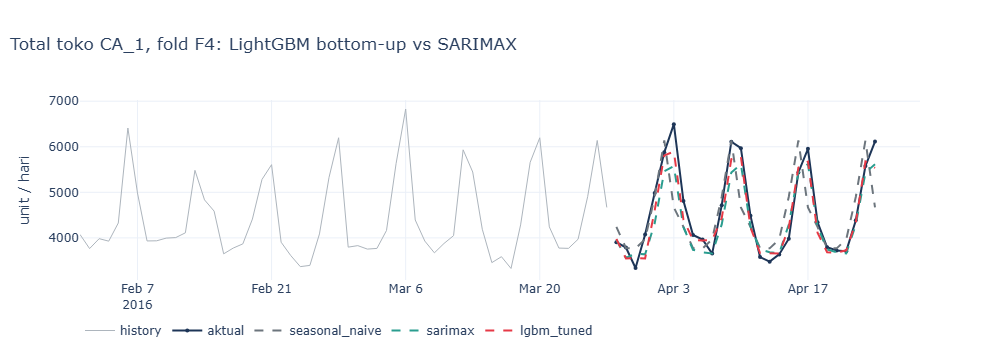

WindowsPath('C:/Projects/demand-forecasting-project/reports/figures/24_forecast_store_f4.png')

In [15]:
agg_truth = load_level_data(config, "agg")
store = agg_truth[agg_truth["series_id"] == config["scope"]["store_id"]]
hist = store[store["d"].between(f4.train_end - 55, f4.train_end)][["date", "sales"]]
actual = store[store["d"].between(f4.valid_start, f4.valid_end)][["date", "sales"]]
actual = actual.rename(columns={"sales": "y_true"})
parts = []
for m in ["seasonal_naive", "sarimax", "lgbm_tuned"]:
    p = pd.read_parquet(PREDS / f"{m}_agg.parquet")
    p = p[(p["series_id"].astype(str) == config["scope"]["store_id"]) & (p["fold"] == "F4")]
    parts.append(p.merge(store[["d", "date"]], on="d")[["date", "y_pred"]].assign(model=m))
fig = plots.plot_forecast_vs_actual(
    hist, actual, pd.concat(parts), title="Total toko CA_1, fold F4: LightGBM bottom-up vs SARIMAX"
)
fig.show()
plots.save_png(fig, "24_forecast_store_f4", config)

## Key findings

1. **LightGBM global adalah model terbaik** di metrik utama: WRMSSE-lite semua item **0,801 ± 0,009** (tuned), 4,7% lebih baik dari benchmark Moving Average 28 hari (0,841). Di level agregat, hasil bottom-up (RMSSE 0,55–0,56) jauh mengalahkan SARIMAX (0,66) yang dilatih khusus per series agregat.
2. **Objective tweedie terbaik** untuk data yang 72% intermittent. Poisson dan L2 tertinggal, terutama di level agregat.
3. **Tuning Optuna hanya memberi tambahan kecil** (0,8045 → 0,8010, ±0,4%, masih di dalam simpangan antar-fold). Akurasi terutama datang dari fitur. Versi tuned dipakai sebagai kandidat final karena terbaik di metrik utama (WRMSSE item), dengan catatan sedikit lebih buruk di agregat dibanding default.
4. **Fitur paling berpengaruh** adalah level penjualan terkini (`roll_mean_28/56`), identitas item, panjang run nol, dan pola mingguan. SHAP mengonfirmasi bahwa arah pengaruhnya masuk akal: penjualan tinggi naik, lama tidak terjual turun, akhir pekan naik, harga di atas rata-rata turun.
5. **Kalender krusial, harga marginal.** Membuang kalender merusak agregat (+79% RMSSE), sedangkan membuang harga hampir tidak berpengaruh di toko ini.
6. **Keunggulan terbesar di item smooth/erratic.** Di item intermittent/lumpy semua model setara, sehingga ketidakpastian di kelas itu harus ditangani lewat safety stock (Fase 7).
7. **Strategi direct berhasil:** error tidak memburuk sepanjang horizon 28 hari.

**Langkah berikutnya (Fase 6):** evaluasi **sekali** di test set d_1914–d_1941 dengan model terpilih, tanpa tuning ulang.